In [6]:
#Librerias
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import sys
import os

sys.path.append(os.path.abspath(".."))

from src.limpieza import limpieza_datos



In [7]:
# Cargar dataset
df = pd.read_csv("../data/Spotify_Tracks_Dataset.csv")

df_limpio = limpieza_datos(df)


df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [8]:
# Dimensiones del dataset
df.shape

(114000, 21)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [10]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [11]:
# Resumen de valores nulos
null_summary = pd.DataFrame({
    'Valores nulos': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df) * 100)
})

null_summary[null_summary['Valores nulos'] > 0]

,Valores nulos,Porcentaje (%)
artists,1,0.000877
album_name,1,0.000877
track_name,1,0.000877


In [12]:
# Mostrar registros que contienen valores nulos
df[df.isnull().any(axis=1)]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [13]:
# Cantidad de registros duplicados
df.duplicated().sum()

np.int64(0)

In [14]:
df['track_id'].duplicated().sum()

np.int64(24259)

In [15]:
# Identificar un track_id que aparece más de una vez
duplicados_id = df[df['track_id'].duplicated(keep=False)]

duplicados_id[['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'track_genre']].head(10)

,track_id,artists,album_name,track_name,popularity,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,acoustic
5,01MVOl9KtVTNfFiBU9I7dc,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,acoustic
6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,acoustic
7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,acoustic
9,7k9GuJYLp2AzqokyEdwEw2,Ross Copperman,Hunger,Hunger,56,acoustic
12,4ptDJbJl35d7gQfeNteBwp,Dan Berk,Solo,Solo,52,acoustic
13,0X9MxHR1rTkEHDjp95F2OO,Anna Hamilton,Bad Liar,Bad Liar,62,acoustic
16,6xKeQgzfjixSUld14qUezm,Andrew Foy;Renee Foy,ily (i love you baby),ily (i love you baby),56,acoustic
17,4Yo0igmcoNyat1secaH0OD,Andrew Foy;Renee Foy,At My Worst,At My Worst,54,acoustic


In [16]:
# Seleccionar un track_id repetido
track_repetido = df['track_id'].value_counts().loc[lambda x: x > 1].index[0]

# Mostrar todos los registros de ese track_id
df[df['track_id'] == track_repetido]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
8315,8315,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,blues
19759,19759,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,country
34728,34728,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,folk
62226,62226,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,j-pop
63087,63087,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,j-rock
82064,82064,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,power-pop
84129,84129,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,psych-rock
99727,99727,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,singer-songwriter
102732,102732,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Straight Up (Remastered 2010 / Deluxe Edition),Baby Blue - Remastered 2010,67,217346,False,0.623,0.876,...,-7.788,1,0.066,0.0189,0.0134,0.0728,0.515,124.431,4,songwriter


In [17]:
# Revisar los primeros y últimos valores de la columna
df['Unnamed: 0'].head(), df['Unnamed: 0'].tail()

(0    0
 1    1
 2    2
 3    3
 4    4
 Name: Unnamed: 0, dtype: int64,
 113995    113995
 113996    113996
 113997    113997
 113998    113998
 113999    113999
 Name: Unnamed: 0, dtype: int64)

In [18]:
print("Artistas:", df['artists'].nunique())
print("Álbumes:", df['album_name'].nunique())
print("Canciones:", df['track_name'].nunique())
print("Géneros:", df['track_genre'].nunique())

Artistas: 31437
Álbumes: 46589
Canciones: 73608
Géneros: 114


In [19]:
df['track_genre'].value_counts()

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
               ... 
techno         1000
trance         1000
trip-hop       1000
turkish        1000
world-music    1000
Name: count, Length: 114, dtype: int64

In [20]:
# Estadísticas descriptivas de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500000,32909.109681,0.000,28499.75000,56999.500000,85499.2500,113999.000
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996


In [21]:
# Revisar registros con tempo igual a 0
df[df['tempo'] == 0][
    ['track_name', 'artists', 'tempo', 'duration_ms', 'track_genre']
].head(10)

,track_name,artists,tempo,duration_ms,track_genre
4131,The Departure,Max Richter;Lang Lang,0.0,151506,ambient
4379,The End of Childhood (feat. Jack Liebeck),Dario Marianelli;Jack Liebeck;Benjamin Wallfisch,0.0,73266,ambient
4664,Ferme Les Yeux,Sylvain Chauveau,0.0,68493,ambient
45670,Campomoro,Little Symphony,0.0,148711,guitar
45720,Ritornello,Little Symphony,0.0,102000,guitar
45729,Amager,Little Symphony,0.0,133624,guitar
45773,Ionian,Little Symphony,0.0,93125,guitar
59221,Yes! No! I Mean Yes! No I Don't!,Leila Bela,0.0,38333,iranian
59310,The Exorsism Begins...,Leila Bela,0.0,8586,iranian
59473,Leaving Her Quantum Journey Behind...,Leila Bela,0.0,50186,iranian


In [22]:
# Cantidad de registros con tempo igual a 0
(df['tempo'] == 0).sum()

np.int64(157)

In [23]:
# Distribución de popularidad
df['popularity'].describe()

count    114000.000000
mean         33.238535
std          22.305078
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64

In [24]:
# Cantidad de canciones por nivel de popularidad
df['popularity'].value_counts().sort_index().head(20)

popularity
0     16020
1      2140
2      1036
3       585
4       389
5       599
6       426
7       465
8       544
9       525
10      733
11      797
12      810
13      695
14      544
15      601
16      972
17     1119
18     1455
19     1612
Name: count, dtype: int64

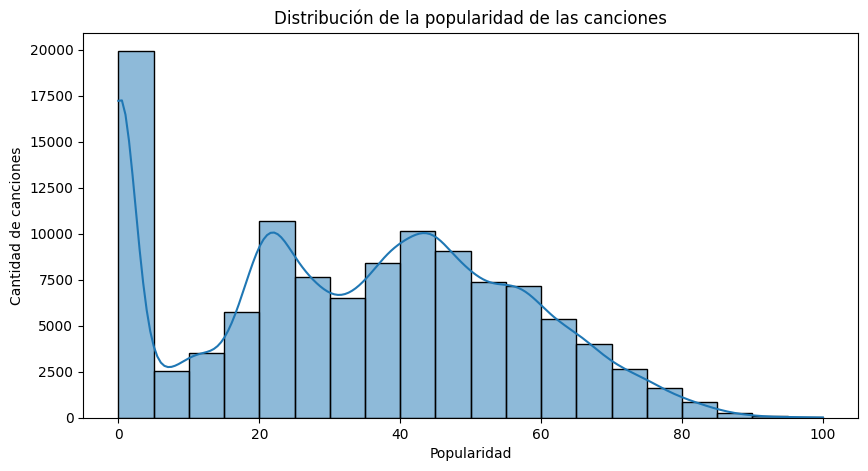

In [25]:
plt.figure(figsize=(10, 5))

sns.histplot(df_limpio['popularity'], bins=20, kde=True)

plt.title('Distribución de la popularidad de las canciones')
plt.xlabel('Popularidad')
plt.ylabel('Cantidad de canciones')

plt.savefig("../images/distribucion_popularity.png", dpi=300, bbox_inches="tight")

plt.show()

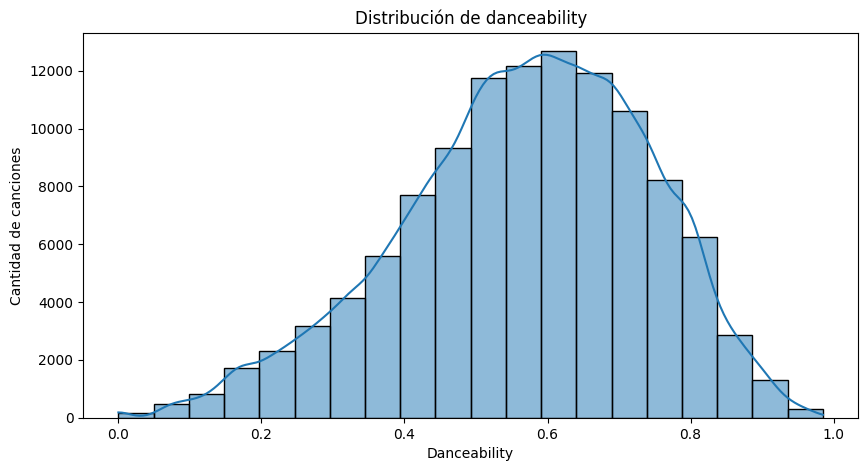

In [26]:
plt.figure(figsize=(10, 5))

sns.histplot(df_limpio['danceability'], bins=20, kde=True)

plt.title('Distribución de danceability')
plt.xlabel('Danceability')
plt.ylabel('Cantidad de canciones')

plt.savefig("../images/distribucion_danceability.png",
            dpi=300, bbox_inches="tight")

plt.show()

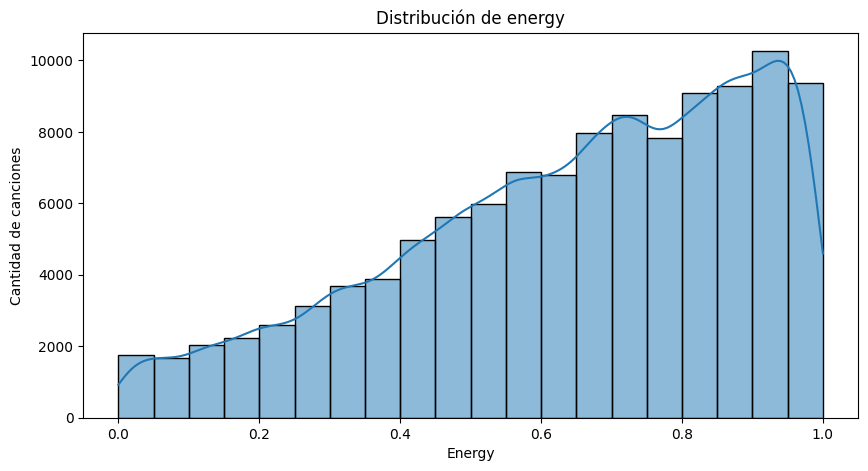

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(df_limpio['energy'], bins=20, kde=True)

plt.title('Distribución de energy')
plt.xlabel('Energy')
plt.ylabel('Cantidad de canciones')

plt.savefig("../images/distribucion_energy.png",
            dpi=300, bbox_inches="tight")

plt.show()

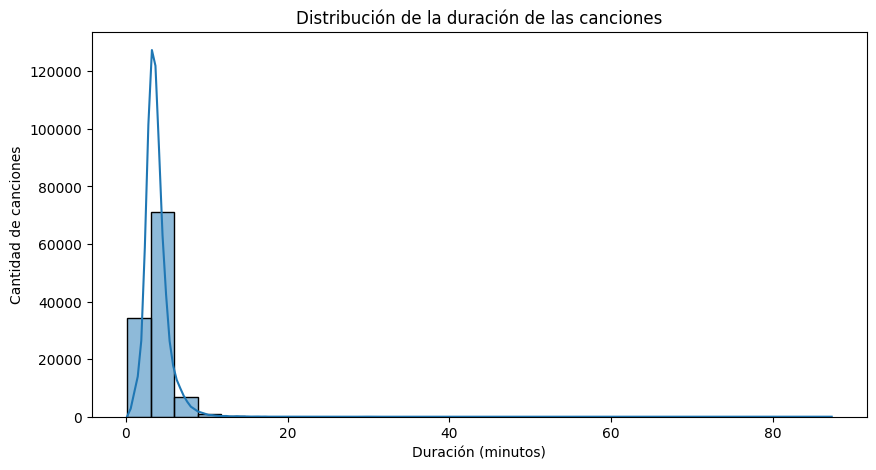

In [34]:
plt.figure(figsize=(10, 5))

duracion_min = df_limpio['duration_ms'] / 60000

sns.histplot(duracion_min, bins=30, kde=True)

plt.title('Distribución de la duración de las canciones')
plt.xlabel('Duración (minutos)')
plt.ylabel('Cantidad de canciones')

plt.savefig("../images/distribucion_duracion.png",
            dpi=300, bbox_inches="tight")

plt.show()

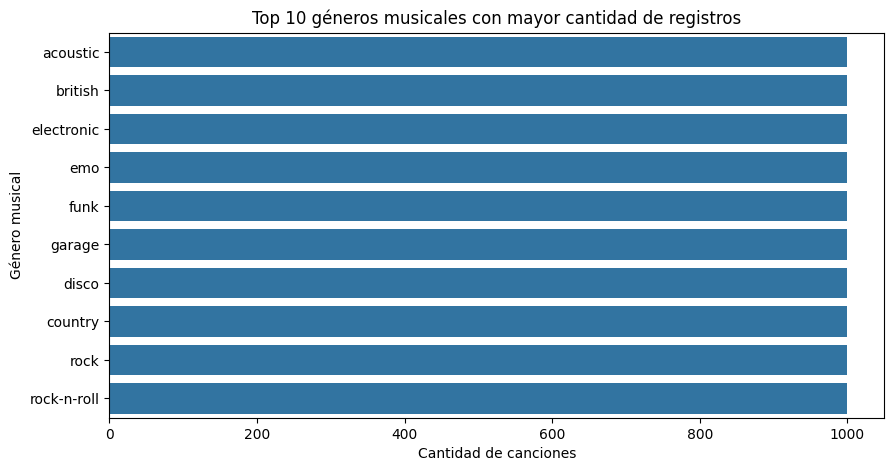

In [35]:
top_generos = df_limpio['track_genre'].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_generos.values,
    y=top_generos.index
)

plt.title('Top 10 géneros musicales con mayor cantidad de registros')
plt.xlabel('Cantidad de canciones')
plt.ylabel('Género musical')

plt.savefig("../images/top_10_generos.png",
            dpi=300, bbox_inches="tight")

plt.show()

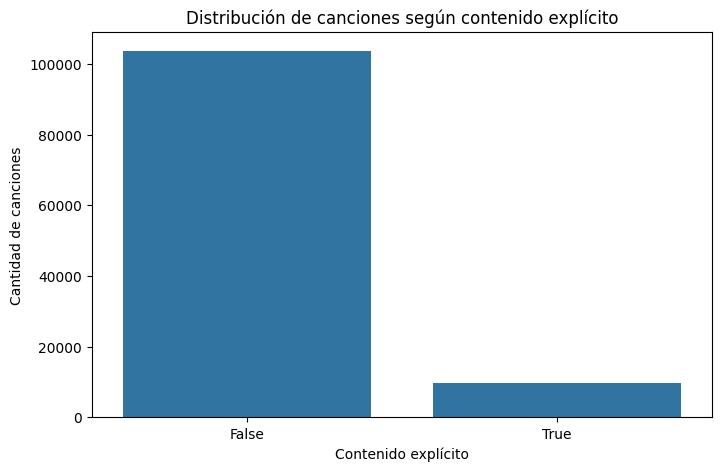

In [36]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_limpio, x='explicit')

plt.title('Distribución de canciones según contenido explícito')
plt.xlabel('Contenido explícito')
plt.ylabel('Cantidad de canciones')

plt.savefig("../images/distribucion_explicit.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [31]:
# Porcentaje de canciones con y sin contenido explícito
df['explicit'].value_counts(normalize=True).mul(100).round(2)

explicit
False    91.45
True      8.55
Name: proportion, dtype: float64

In [32]:



print("Dimensiones originales:", df.shape)
print("Dimensiones limpias:", df_limpio.shape)

Dimensiones originales: (114000, 21)
Dimensiones limpias: (113549, 20)
